In [9]:
from generate_repeater import generate_repeater_from_dist
import matplotlib.pyplot as plt
from zn2_stat import zn2_stat
import numpy as np
import scipy as sp

In [36]:
# Make the whole thing into a function:
# 

def distribution_testing(toas, colors, distribution, saving = False, title = "untitled"):
    dt = np.diff(toas)
    counts, bins, bars =  plt.hist(dt, bins = 100, weights=np.ones_like(dt) / len(dt))
    args = sp.stats.weibull_min.fit(dt)
    results = sp.stats.kstest(dt, 'weibull_min', args = args)

    # Set up plotting

    fig, ax = plt.subplots(1, 3)
    fig.set_figwidth(20)
    fig.set_figheight(5)

    # CDF fit

    ax[0].scatter(bins[:-1], np.cumsum(counts), color = colors[0], label = "generated data", linewidth = 2)
    ax[0].plot(bins[:-1], sp.stats.weibull_min.cdf(bins[:-1], c = args[0], loc = 0, scale = args[2]),
                                                    color = colors[1], linestyle = "--", label = f"fit p={round(results[1],3)}",
                                                    linewidth = 3.5)
    ax[0].set_xlabel("$\Delta$t[d]", fontsize = 15)
    ax[0].set_ylabel("Cumulative Probability", fontsize = 15)
    ax[0].tick_params(length = 5, width = 1, labelsize = 9)
    ax[0].legend(fontsize = 10)
    ax[0].set_title("CDF", fontsize = 15)
#    ax[0].set_yscale("log")
#    ax[0].set_xscale("log")


    # Histogram fit

    ax[1].hist(dt, bins = 100, color = colors[0], fill = True, alpha = 1, density = True, label = "generated data")
    ax[1].plot(bins, sp.stats.weibull_min.pdf(bins, c = args[0], loc = args[1], scale = args[2]), color = colors[1], linestyle = "--",
                                                label = f"fit p={round(results[1], 5)}\n shape = {round(args[0],3)}\n scale = {round(args[2],3)}", linewidth = 2)

    ax[1].set_xlabel("$\Delta$t[d]", fontsize = 20)
    ax[1].set_ylabel("#in bin ()", fontsize = 20)
    ax[1].tick_params(length = 5, width = 1, labelsize = 9)
    ax[1].legend(fontsize = 10)
    ax[1].set_title("wait time distribution", fontsize = 15)
    ax[1].set_yscale("log")
 #   ax[1].set_xscale("log")

    #Zn^2 plotting

    zn_sq, freqs, pvals = zn2_stat(False, 4, highest_freq = 0.20, plotting = True, saving = False, toa = toas)
    fig.suptitle(distribution, fontsize = 20)
    if saving:
        fig.savefig(f"D:\Thesis\\figures\\{title}", bbox_inches = "tight")
    print(max(freqs))

<class 'numpy.ndarray'>
[7.35858138e-03 1.02038093e-02 2.06264908e-02 ... 1.00952612e+02
 1.00964462e+02 1.00967730e+02]
0.2


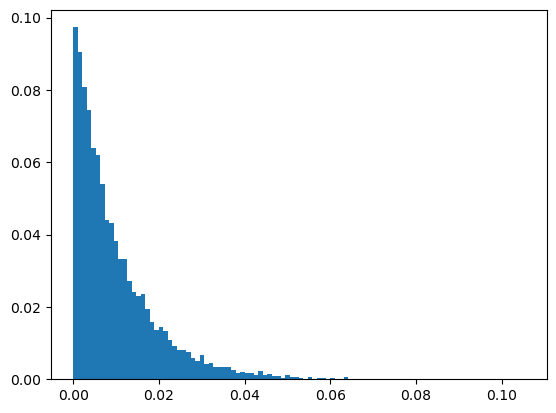

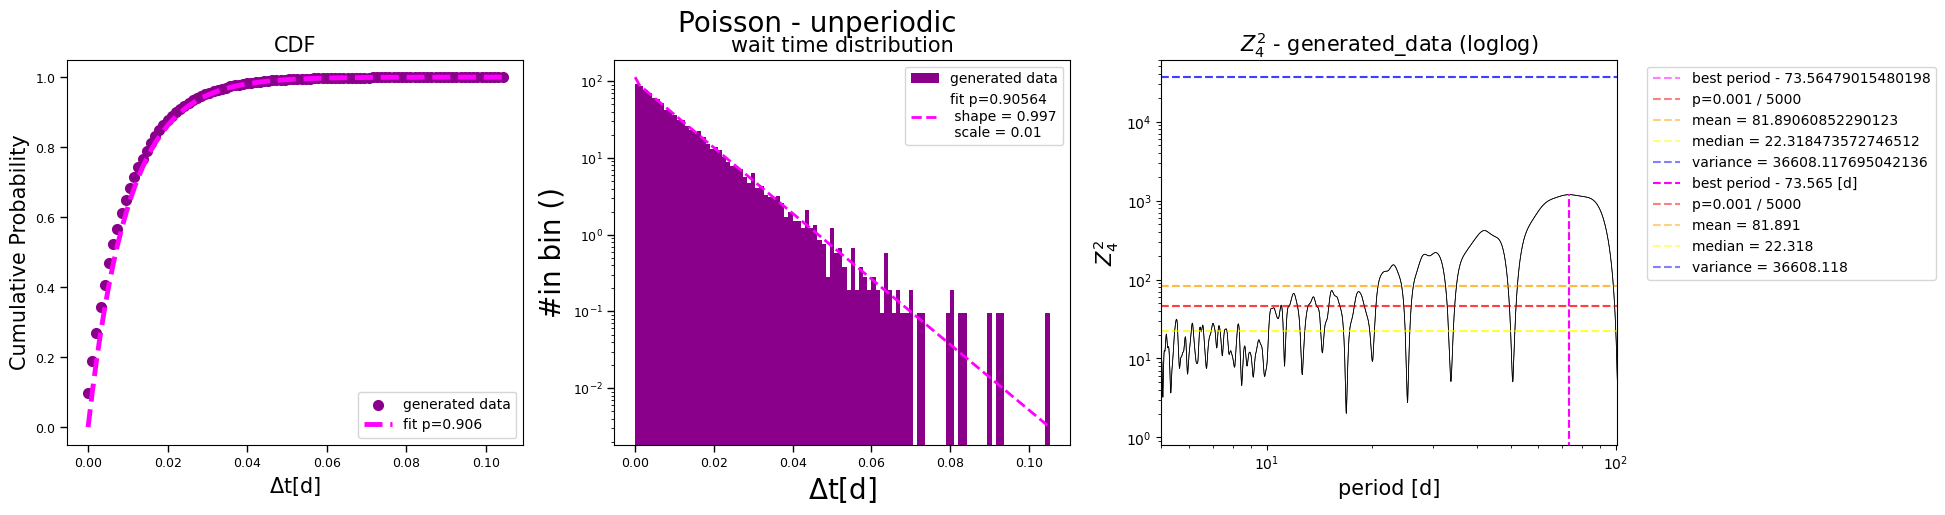

In [37]:
toas = generate_repeater_from_dist(10000, dist = "poisson", rate = 100)
distribution_testing(toas, colors = ["darkmagenta", "magenta"], distribution = "Poisson - unperiodic", title = "Poisson_gen_unperiodic", saving = True)



<class 'numpy.ndarray'>
[1.26445175e-02 1.77573884e-02 2.32729238e-02 ... 9.94200274e+01
 9.94261242e+01 9.94382997e+01]
0.2


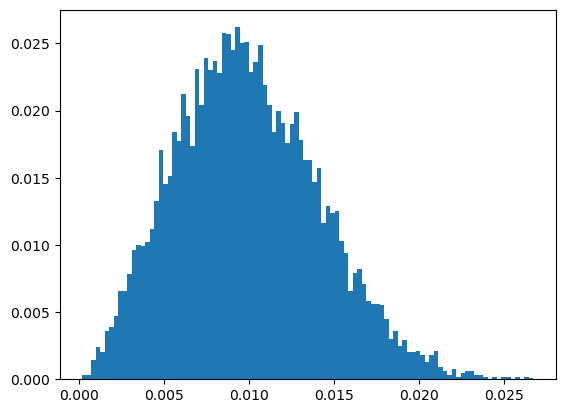

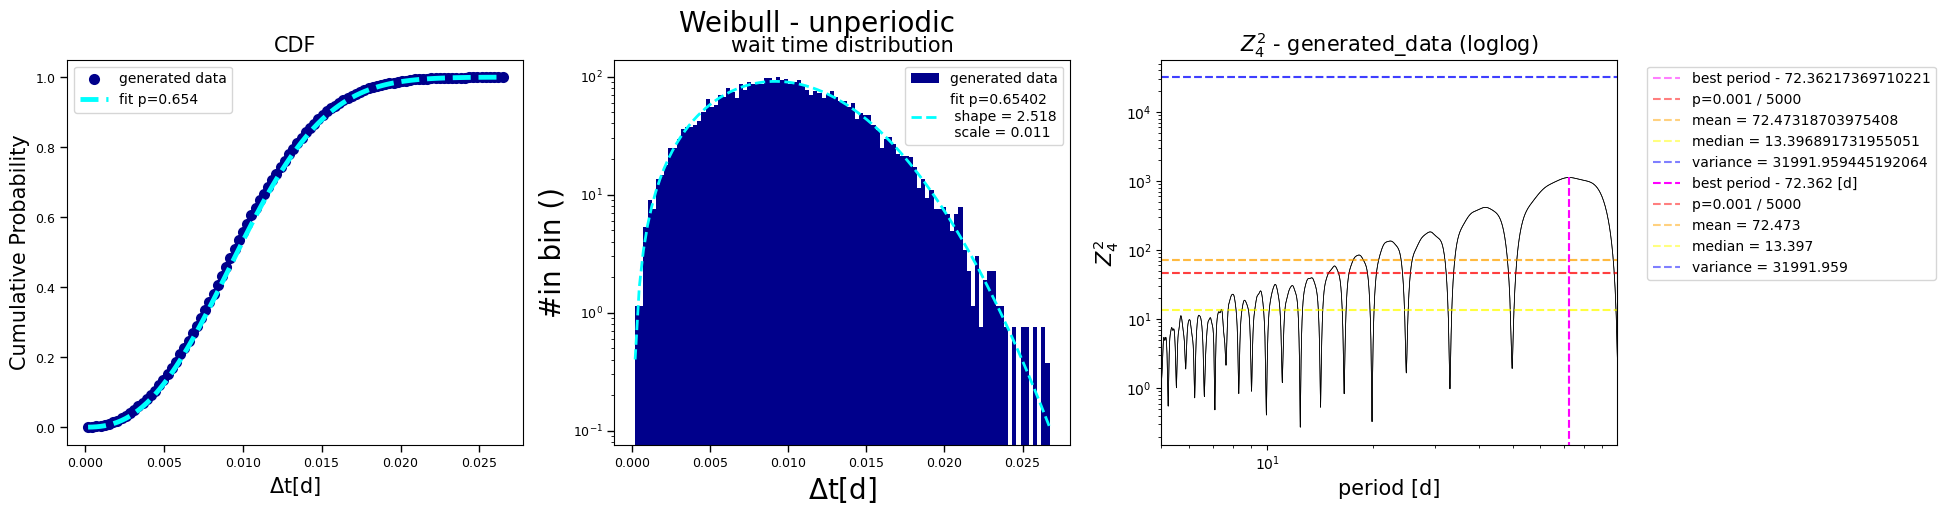

In [38]:

toas= generate_repeater_from_dist(10000, dist = "weibull", shape = 2.5, mean_wait = 1/100)
distribution_testing(toas = toas, colors = ["darkblue", "cyan"], distribution = "Weibull - unperiodic", saving = True, title = "weibull_gen_unperiodic")


<class 'numpy.ndarray'>
[4.39781080e-03 1.00629855e+00 2.00029848e+00 ... 3.62230068e+04
 3.62350063e+04 3.62360035e+04]
0.2


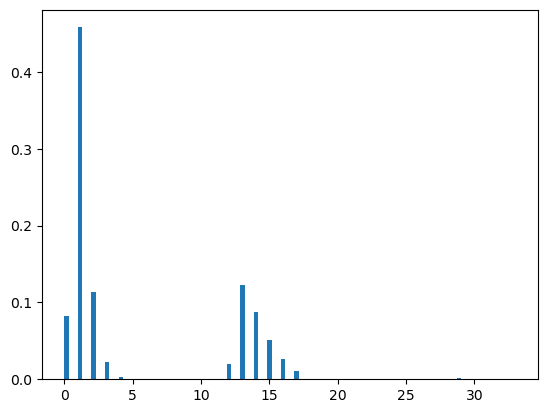

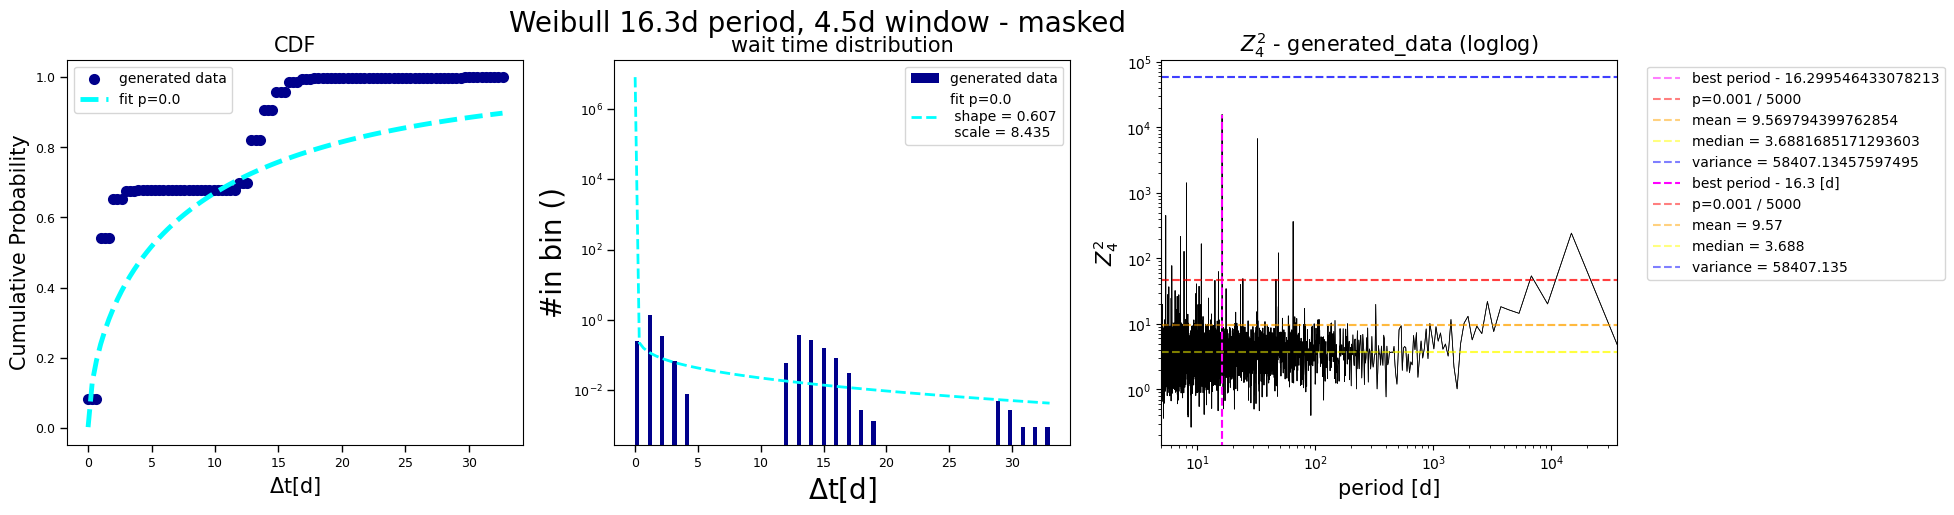

In [39]:
from generate_repeater import observing_window_mask

toas= generate_repeater_from_dist(1000000, dist = "weibull", shape = 2.5, mean_wait = 1/100, period = 16.3, window = 4.5)
toas = toas[observing_window_mask(toas)]
distribution_testing(toas = toas, colors = ["darkblue", "cyan"], distribution = "Weibull 16.3d period, 4.5d window - masked", saving = True, title = "weibull_gen_periodic_r3_masked")


<class 'numpy.ndarray'>
[1.00165892e+00 2.00478082e+00 1.70065650e+01 1.90001090e+01
 2.00061043e+01 2.00063299e+01 3.50035883e+01 3.70004000e+01
 3.70021580e+01 5.00006290e+01 5.00050327e+01 5.30017568e+01
 5.30024350e+01 6.60046306e+01 8.30010229e+01 8.40035215e+01
 8.50013118e+01 8.50020328e+01 9.80017791e+01 9.90008311e+01
 9.90051967e+01 1.01000684e+02 1.01002988e+02 1.16002818e+02
 1.17004987e+02 1.18002662e+02 1.18005648e+02 1.31002783e+02
 1.31003683e+02 1.31004204e+02 1.33006617e+02 1.34000845e+02
 1.34002036e+02 1.34004696e+02 1.47001677e+02 1.47004125e+02
 1.49002120e+02 1.49003625e+02 1.51000825e+02 1.63002820e+02
 1.63003179e+02 1.64000163e+02 1.67005738e+02 1.83005281e+02
 1.96000077e+02 1.97003745e+02 1.98005432e+02 1.99004052e+02
 2.16006547e+02 2.30003835e+02 2.45004067e+02 2.46002432e+02
 2.47000041e+02 2.47003864e+02 2.47004943e+02 2.47005598e+02
 2.48001548e+02 2.62003153e+02 2.81003067e+02 2.94002953e+02
 2.95001887e+02 2.97000410e+02 3.10002506e+02 3.14003978e+02


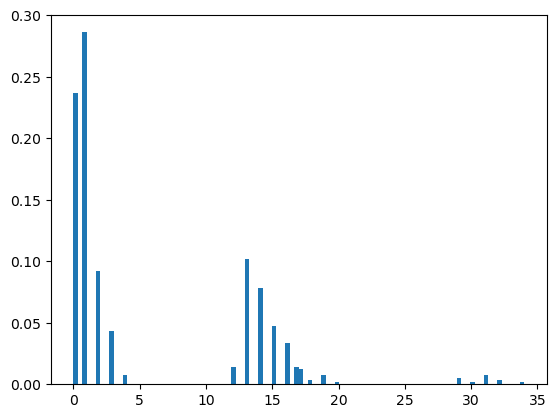

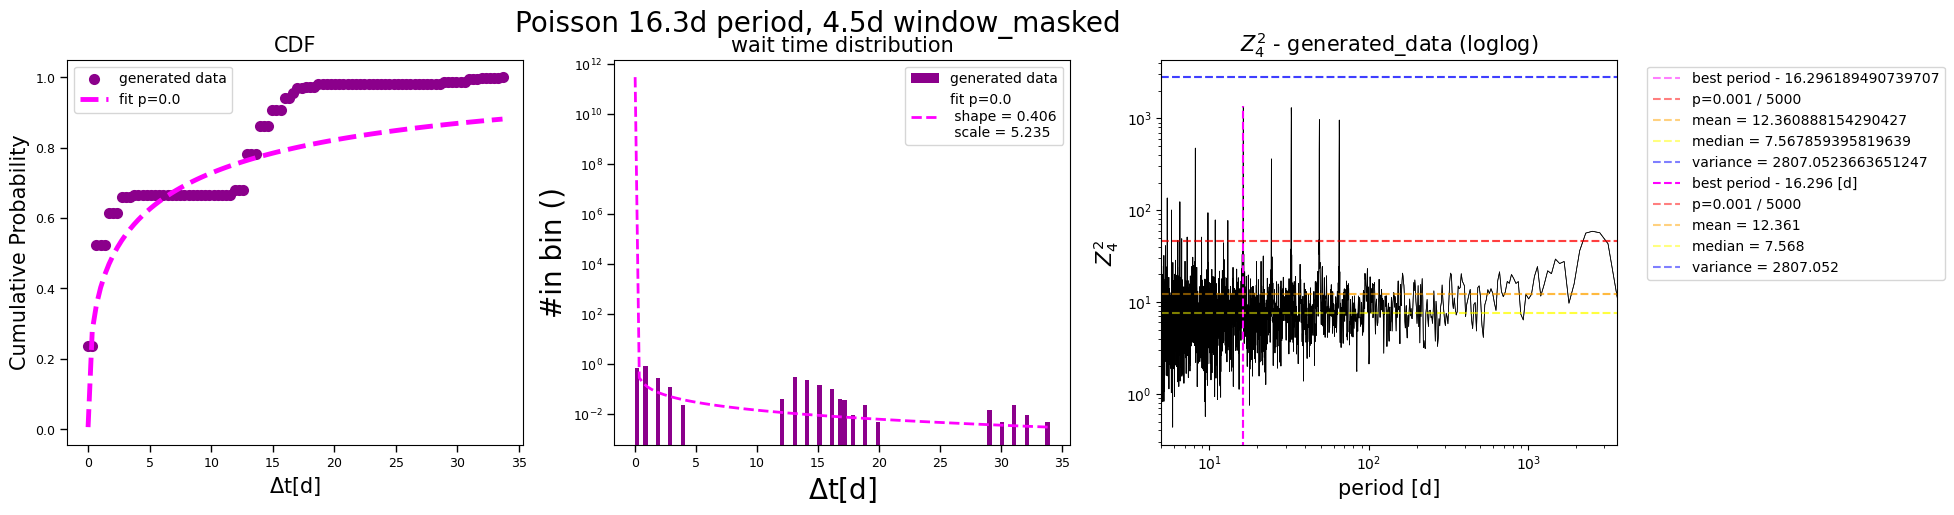

In [40]:
toas= generate_repeater_from_dist(100000, dist = "poisson", rate = 100, period = 16.3, window = 4.5)
toas = toas[observing_window_mask(toas)]
distribution_testing(toas = toas, colors = ["darkmagenta", "magenta"], distribution = "Poisson 16.3d period, 4.5d window_masked", saving = True, title = "poisson_gen_periodic_r3_mas")


<class 'numpy.ndarray'>
[6.65316045e-03 9.56411436e-03 1.39842814e-02 ... 3.61926020e+03
 3.61927111e+03 3.61928235e+03]
0.2


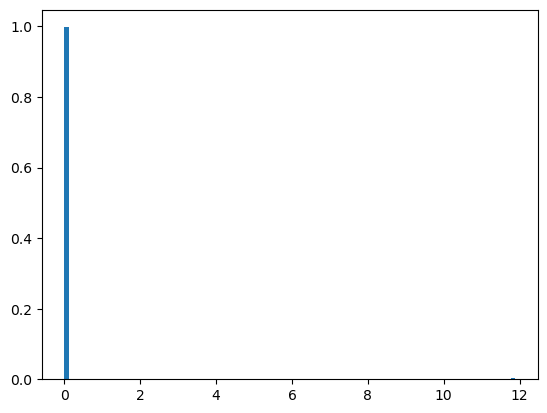

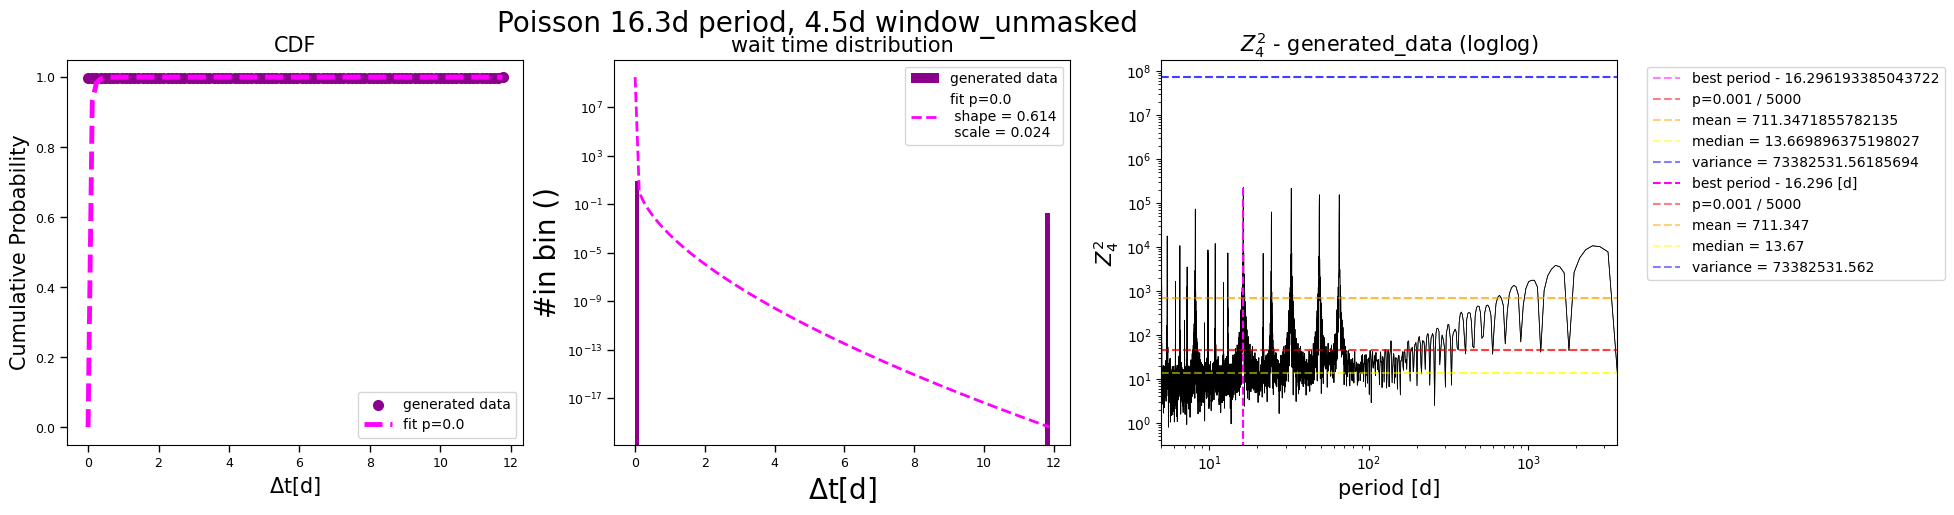

In [41]:
toas= generate_repeater_from_dist(100000, dist = "poisson", rate = 100, period = 16.3, window = 4.5)
distribution_testing(toas = toas, colors = ["darkmagenta", "magenta"], distribution = "Poisson 16.3d period, 4.5d window_unmasked", saving = True, title = "poisson_gen_periodic_r3_unmasked")


<class 'numpy.ndarray'>
[2.37522087e-03 1.73237490e-02 3.08231233e-02 ... 3.62055985e+03
 3.62056787e+03 3.62058171e+03]
0.2


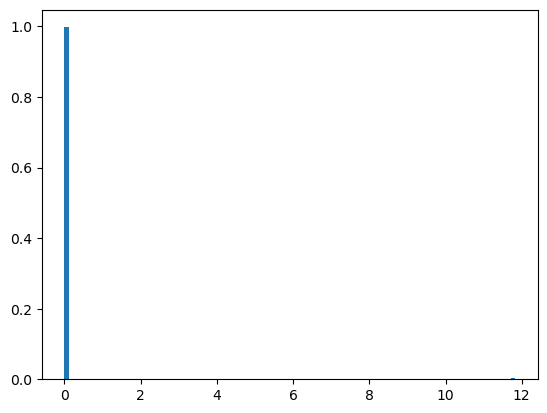

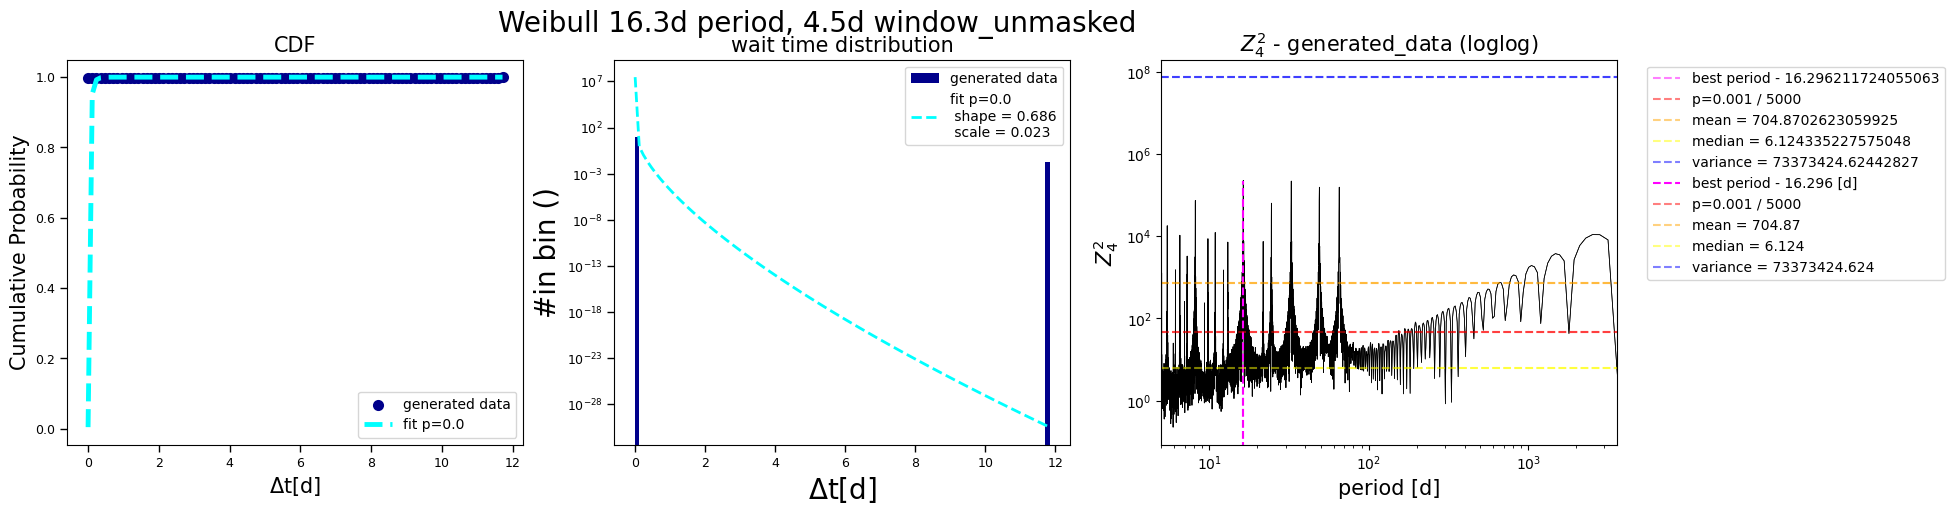

In [44]:
toas= generate_repeater_from_dist(100000, dist = "weibull", rate = 100,shape = 2.5, mean_wait = 1/100, period = 16.3, window = 4.5)
distribution_testing(toas = toas, colors = ["darkblue", "cyan"], distribution = "Weibull 16.3d period, 4.5d window_unmasked", saving = True, title = "weibull_gen_periodic_r3_unmasked")
